## 1. Initialization and Data Preparation
In this section, we initialize our end-to-end inference pipeline (`MercariPricePredictor`) and load a random sample of the validation dataset. To prevent out-of-memory errors during the computationally expensive SHAP calculations, we restrict the analysis to a subset of 2,000 listings. The raw data is passed through our preprocessing and text-vectorization pipeline to generate the final 212 features, and the LightGBM model generates log-price predictions.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
import sys
import os
import __main__

# Add src to path to import the pipeline
sys.path.append(os.path.abspath('../src'))

# CRITICAL FIX: Map the preprocessor to the notebook's __main__ namespace
from preprocessing import MercariPreprocessor
__main__.MercariPreprocessor = MercariPreprocessor

from prediction_pipeline import MercariPricePredictor

# Initialize the predictor
predictor = MercariPricePredictor(artifact_dir="../data")

# Load a small sample of raw data (e.g., 2000 rows) to prevent SHAP from crashing your RAM
raw_data = pd.read_csv('../data/train.tsv', sep='\t', nrows=2000)

# Clean out zero-price rows as per project rules
raw_data = raw_data[raw_data['price'] > 0].copy()

# Generate the 212 features and actual log prices
X_sample = predictor.prepare_features(raw_data)
y_actual_log = np.log1p(raw_data['price'])

# Get predictions
y_pred_log = predictor.model.predict(X_sample)

## 2. Global Model Performance: Actual vs. Predicted & Residuals
To evaluate the model's performance in a business-interpretable context, we must invert the `log1p` transformation applied during training using `np.expm1()`. 

This section generates two visual diagnostics:
1. **Actual vs. Predicted Prices:** A scatter plot comparing our model's suggested prices against the true market prices. The red dashed line represents perfect predictions.
2. **Residual Distribution:** A histogram showing the prediction errors (Actual Price - Predicted Price). A normal distribution centered around zero indicates that our model's errors are random rather than systematically biased.

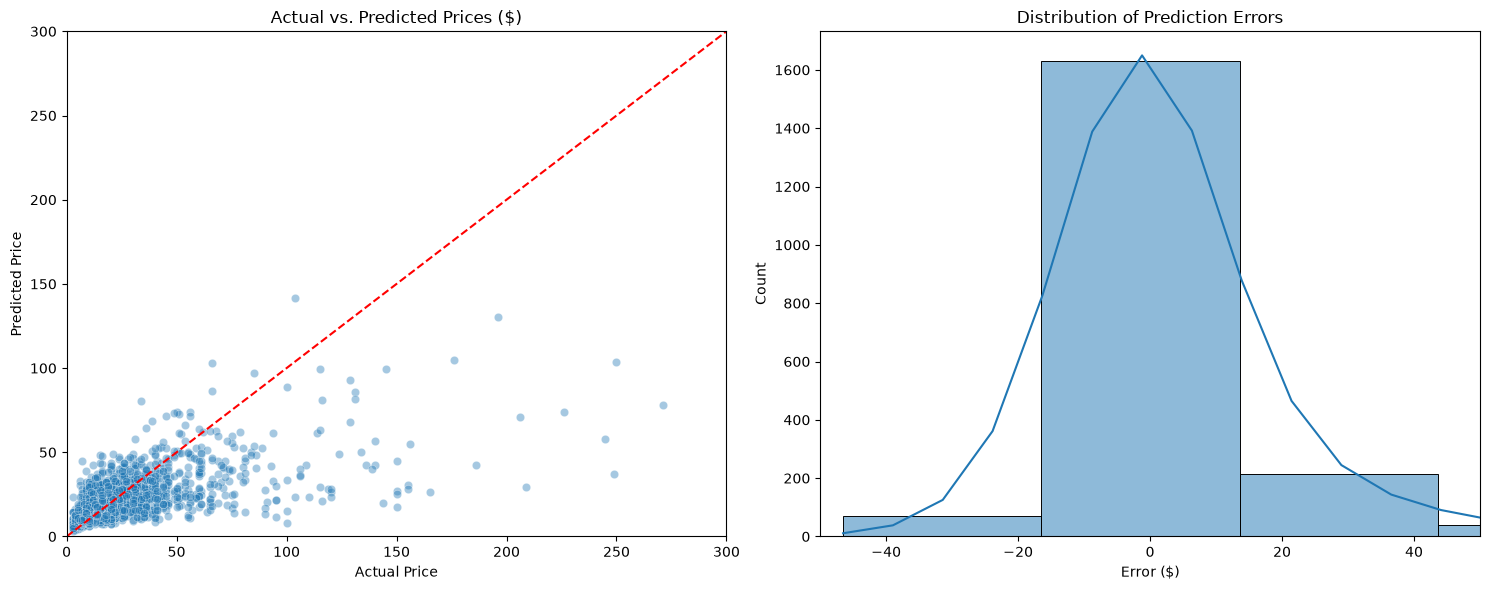

In [5]:
# Convert back to actual dollars for the business report
y_actual_dollars = np.expm1(y_actual_log)
y_pred_dollars = np.expm1(y_pred_log)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Actual vs Predicted
sns.scatterplot(x=y_actual_dollars, y=y_pred_dollars, alpha=0.4, ax=axes[0])
axes[0].plot([0, 300], [0, 300], '--', color='red') # Reference line
axes[0].set_title('Actual vs. Predicted Prices ($)')
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
axes[0].set_xlim(0, 300)
axes[0].set_ylim(0, 300)

# Plot 2: Residuals
residuals = y_actual_dollars - y_pred_dollars
sns.histplot(residuals, bins=50, kde=True, ax=axes[1])
axes[1].set_title('Distribution of Prediction Errors')
axes[1].set_xlabel('Error ($)')
axes[1].set_xlim(-50, 50)

plt.tight_layout()
plt.savefig('../data/model_performance.png', dpi=300)
plt.show()

## 3. Model Explainability: SHAP Feature Importance
Machine learning models (like LightGBM) are often treated as "black boxes." To understand *why* the model makes specific pricing decisions, we utilize SHapley Additive exPlanations (SHAP). 

This cell calculates the marginal contribution of every single feature across our sample dataset. The resulting SHAP summary plot ranks the top features by their global impact on the final predicted price, allowing us to see whether categorical attributes (like brand and condition) or engineered text features (derived via SVD from the item description) hold the most predictive power.

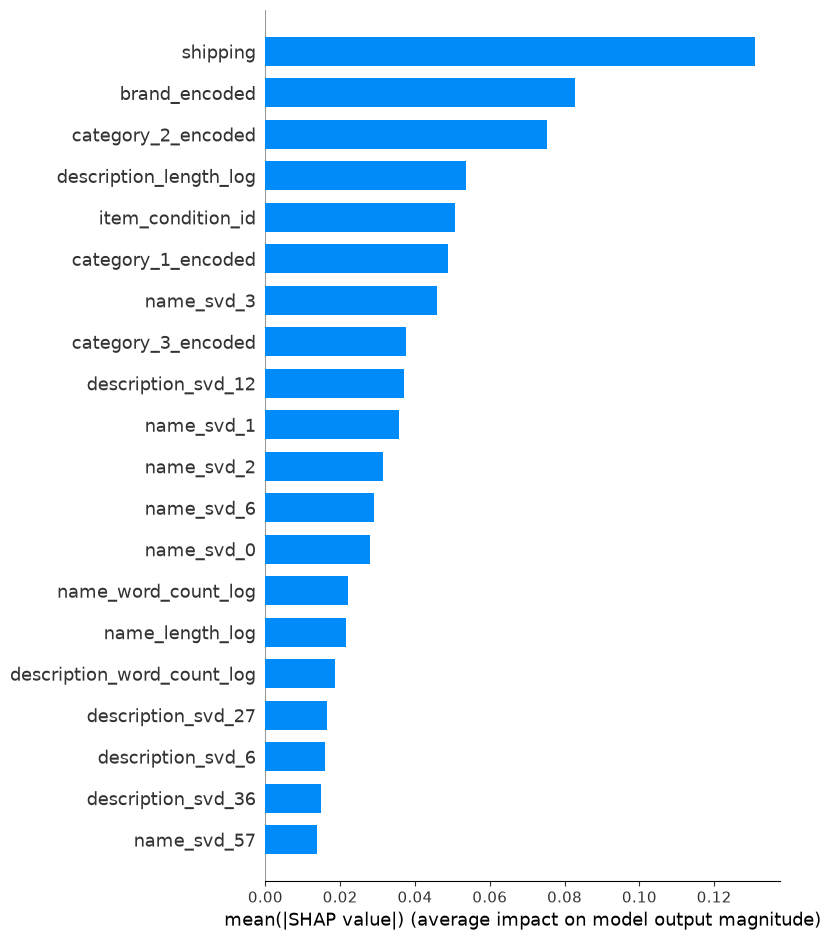

In [6]:
# Initialize SHAP explainer on the LightGBM model
explainer = shap.TreeExplainer(predictor.model)
shap_values = explainer.shap_values(X_sample)

# Generate the summary plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig('../data/shap_summary.png', dpi=300)
plt.show()